# Bessel zeros and grid scale ratios (Fig. 6)

Reproduces Fig. 6 (Sec. 2.4, Appendix G) and checks the two claims the figure rests on.

In polar coordinates the Jacobi-Anger expansion splits the similarity function into a radial
part and angular terms,

$$C(r,\theta) = \sum_j \alpha_{0,j}^2 J_0(k_j r)
  + 2\sum_{n=1}^{\infty}(-1)^n \mathrm{Re}\Big[e^{2in\theta}\sum_j \alpha_{0,j}^2 J_{2n}(k_j r)e^{-2in\phi_j}\Big].$$

**The angular terms can be suppressed.** For a roots-of-unity module of symmetry order $M$ the
inner sum vanishes unless $n$ is a multiple of $M$. With $L$ copies of the module at orientation
offsets $\pi l / (ML)$ the angular terms survive only at multiples of $ML$, and since
$J_\gamma(z) \approx (z/2)^\gamma / \Gamma(\gamma + 1)$ for small $z$, they are negligible
over a wide range of $r$. What remains is the Fourier-Bessel series
$C(r) \approx ML\sum_a \alpha_{0,a}^2 J_0(k_a r)$.

**The ring radii predict grid scale ratios.** A Fourier-Bessel series on $0 \le r \le r_{\max}$
has its wavenumbers at the zeros of $J_0$, so the ratio of neighboring module spacings is the
ratio of successive zeros. These ratios start at 2.30 and decrease slowly toward one
(Fig. 6), so the spacing ratio grows with grid scale rather than staying constant.

`bessel_module_frequencies` and `multiscale_wavevectors` build the spectrum, and
`tests/test_generators.py` checks it against the closed form above.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from scipy.special import j0

from expmap.generators import (
    bessel_module_frequencies,
    block_diag_skew,
    build_generators,
    multiscale_wavevectors,
)
from expmap.linalg import random_orthogonal_matrix, starting_state
from expmap.model import ExponentialMap

NUM_ZEROS = 15  # Fig. 6
K = 5  # rings of the similarity maps below
M = 3
ARENA_SIZE = 6.0
SEED = 0

REPO_ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
FIGURE_DIR = REPO_ROOT / "figures"
FIGURE_DIR.mkdir(exist_ok=True)

first ratios: [2.3  1.57 1.36 1.27]


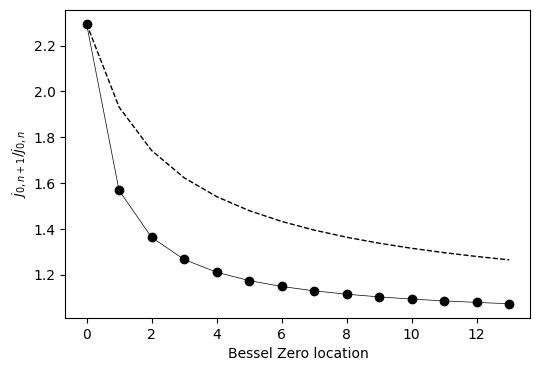

In [2]:
# Fig. 6. The scale cancels in the ratios, which depend on the zeros of J0 alone.
frequencies = bessel_module_frequencies(NUM_ZEROS, arena_size=ARENA_SIZE)
ratios = frequencies[1:] / frequencies[:-1]
cumulative = np.cumsum(ratios) / np.arange(1, len(ratios) + 1)

plt.figure(figsize=(6, 4))
plt.plot(ratios, "ko-", linewidth=0.5)
plt.plot(cumulative, "k--", linewidth=1)
plt.xlabel("Bessel Zero location")
plt.ylabel(r"$j_{0,n+1} / j_{0,n}$")
plt.savefig(FIGURE_DIR / "bessel_zeros.pdf", dpi=300, bbox_inches="tight", transparent=True)
plt.savefig(FIGURE_DIR / "bessel_zeros.png", dpi=300, bbox_inches="tight", transparent=True)

print(f"first ratios: {np.round(ratios[:4], 2)}")

## Suppression of the angular terms

$K = 5$ rings at the first five zeros, each with $M = 3$ hexagonal orientations, in $L$ rotated
copies. With $L = 1$ the lowest angular term is $\cos(6\theta)$ and the hexagonal structure is
visible in the similarity map. With $L = 2$ it is $\cos(12\theta)$ and the map is radial out to
most of the arena.

ring radii k: [0.605 1.388 2.176 2.965 3.754]


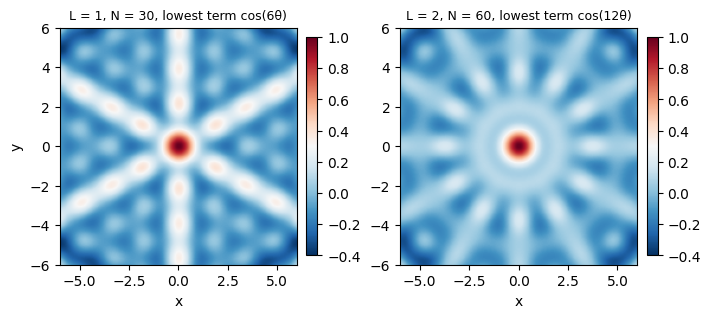

In [3]:
def bessel_model(n_offsets, seed=SEED):
    """K Bessel-spaced rings, M orientations each, in n_offsets rotated copies."""
    k = bessel_module_frequencies(K, arena_size=ARENA_SIZE)
    lambda_x, lambda_y = multiscale_wavevectors(k, M=M, n_offsets=n_offsets)
    N = 2 * len(lambda_x)

    R = random_orthogonal_matrix(N, seed=seed)
    p0 = starting_state(R)
    Gx, Gy = build_generators(block_diag_skew(lambda_x), block_diag_skew(lambda_y), R)
    return ExponentialMap(Gx, Gy), p0, N, k


def similarity_to_origin(model, p0, positions):
    with torch.no_grad():
        origin = model(torch.zeros(1, 2), p0)[0]
        return (model(positions, p0) @ origin).numpy()


extent = (-ARENA_SIZE, ARENA_SIZE, -ARENA_SIZE, ARENA_SIZE)
grid = np.linspace(-ARENA_SIZE, ARENA_SIZE, 201)
X, Y = np.meshgrid(grid, grid, indexing="ij")
positions = torch.tensor(np.stack([X.ravel(), Y.ravel()], axis=1), dtype=torch.float32)

fig, axs = plt.subplots(1, 2, figsize=(7, 3.2), layout="constrained")
for ax, n_offsets in zip(axs, (1, 2)):
    model, p0, N, k = bessel_model(n_offsets)
    similarity = similarity_to_origin(model, p0, positions).reshape(X.shape)
    im = ax.imshow(similarity.T, extent=extent, origin="lower", cmap="RdBu_r", vmin=-0.4, vmax=1.0)
    ax.set_title(f"L = {n_offsets}, N = {N}, lowest term cos({2 * M * n_offsets}θ)", fontsize=9)
    ax.set_xlabel("x")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
axs[0].set_ylabel("y")
fig.savefig(FIGURE_DIR / "bessel_similarity_maps.svg", dpi=300, bbox_inches="tight")
fig.savefig(FIGURE_DIR / "bessel_similarity_maps.png", dpi=300, bbox_inches="tight")

print(f"ring radii k: {np.round(k, 3)}")

## The radial series

With the angular terms suppressed, the similarity averaged over direction is the Fourier-Bessel
series $ML\sum_a \alpha_{0,a}^2 J_0(k_a r)$ with uniform coefficients $\alpha_{0,a}^2 = 1/N$.

max |empirical - Fourier-Bessel series| = 1.54e-07


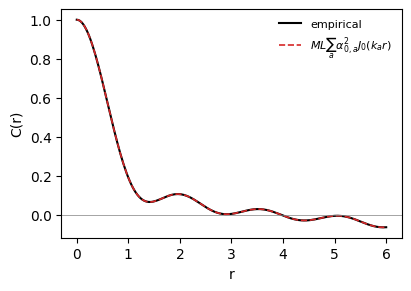

In [4]:
L = 2
model, p0, N, k = bessel_model(L)

theta = np.linspace(0, 2 * np.pi, 360, endpoint=False)
r = np.linspace(0, ARENA_SIZE, 200)
rings = torch.tensor(
    np.stack([np.outer(r, np.cos(theta)).ravel(), np.outer(r, np.sin(theta)).ravel()], axis=1), dtype=torch.float32
)
empirical = similarity_to_origin(model, p0, rings).reshape(len(r), len(theta)).mean(axis=1)
series = np.array([np.sum((2 / N) * M * L * j0(k * ri)) for ri in r])

print(f"max |empirical - Fourier-Bessel series| = {np.abs(empirical - series).max():.2e}")

fig, ax = plt.subplots(figsize=(4, 2.8), layout="constrained")
ax.plot(r, empirical, "k", linewidth=1.5, label="empirical")
ax.plot(r, series, "C3--", linewidth=1.2, label=r"$ML\sum_a \alpha_{0,a}^2 J_0(k_a r)$")
ax.axhline(0, color="gray", linewidth=0.5)
ax.set_xlabel("r")
ax.set_ylabel("C(r)")
ax.legend(fontsize=8, frameon=False)